<a href="https://colab.research.google.com/github/ZidAvwa/PCVK_Ganjil_2026/blob/main/Week7.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

**Part 0 - Setup + Drive**

---

In [ ]:
from google.colab import drive
from google.colab.patches import cv2_imshow
import numpy as np
import matplotlib.pyplot as plt
import cv2 as cv
import math
from PIL import Image as im

drive.mount('/content/drive')

IMAGES = '/content/drive/MyDrive/PCVK Semester 5/Images'

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).


In [ ]:
def load_image(name, flag=cv.IMREAD_COLOR, fallback=None):
    img = cv.imread(IMAGES + '/' + name, flag)
    if img is None and fallback is not None:
        print('%s not found, using %s instead' % (name, fallback))
        img = cv.imread(IMAGES + '/' + fallback, flag)
    if img is None:
        raise FileNotFoundError('Image not found: ' + IMAGES + '/' + name)
    return img

def calculate_psnr(img1, img2):
    mse = np.mean((img1.astype(np.float64) - img2.astype(np.float64)) ** 2)
    if mse == 0:
        return 100.0
    return 20 * math.log10(255.0 / math.sqrt(mse))

def to_display(result, mode='clip'):
    r = np.asarray(result, dtype=np.float64)
    if mode == 'clip':
        return np.clip(r, 0, 255).astype(np.uint8)
    if mode == 'abs':
        r = np.abs(r)
    elif mode == 'norm':
        r = r - r.min()
    top = np.percentile(r, 99.5)
    return np.clip(r / top * 255, 0, 255).astype(np.uint8) if top > 0 else r.astype(np.uint8)

def show_grid(items, cols=3, figsize_per=(5, 5)):
    rows = math.ceil(len(items) / cols)
    plt.figure(figsize=(figsize_per[0] * cols, figsize_per[1] * rows))
    for i, (t, a) in enumerate(items, 1):
        plt.subplot(rows, cols, i)
        plt.imshow(a, cmap='gray', vmin=0, vmax=255)
        plt.title(t, fontsize=10)
        plt.axis('off')
    plt.tight_layout()
    plt.show()

def show_side_by_side(images, titles, figsize=(15, 5)):
    plt.figure(figsize=figsize)
    for i, (img, title) in enumerate(zip(images, titles)):
        if len(img.shape) == 2:
            plt.subplot(1, len(images), i + 1)
            plt.imshow(img, cmap="gray")
        else:
            plt.subplot(1, len(images), i + 1)
            plt.imshow(cv.cvtColor(img, cv.COLOR_BGR2RGB))
        plt.title(title)
        plt.axis("off")
    plt.show()

**Part 1 - Convolution without a library**

---

Convolution follows the algorithm in Section C: for every output pixel, multiply each kernel coefficient `H(k1,k2)` with the image pixel it covers and add everything up. The border problem is handled with padding (zero padding by default, or replicated edge pixels).

- `convolution2d_loops` is the literal pseudo-code with nested loops (slow, used to verify on small images).
- `convolution2d` computes exactly the same sum, but loops only over the kernel offsets `(k1, k2)` and adds a shifted copy of the whole image each time, so it is fast enough for full images (even a 21x21 kernel).

Parameters: input image, kernel, `stride` (shift per step), `padding` (pixels added on every side). As in the module's pseudo-code the kernel is **not flipped** (strictly speaking this is correlation; for symmetric kernels it is identical to convolution).

In [ ]:
def pad_image(image, padding, mode='zero'):
    if padding == 0:
        return image
    if mode == 'zero':
        return np.pad(image, padding, mode='constant', constant_values=0)
    if mode == 'replicate':
        return np.pad(image, padding, mode='edge')
    raise ValueError("mode must be 'zero' or 'replicate'")

def convolution2d_loops(image, kernel, stride=1, padding=0, mode='zero'):
    image = pad_image(np.asarray(image, dtype=np.float64), padding, mode)
    kernel = np.asarray(kernel, dtype=np.float64)
    kh, kw = kernel.shape
    H, W = image.shape
    out_h = (H - kh) // stride + 1
    out_w = (W - kw) // stride + 1
    z = np.zeros((out_h, out_w))
    for y in range(out_h):
        for x in range(out_w):
            s = 0.0
            for k1 in range(kh):
                for k2 in range(kw):
                    s += kernel[k1, k2] * image[y * stride + k1, x * stride + k2]
            z[y, x] = s
    return z

def convolution2d(image, kernel, stride=1, padding=0, mode='zero'):
    image = pad_image(np.asarray(image, dtype=np.float64), padding, mode)
    kernel = np.asarray(kernel, dtype=np.float64)
    kh, kw = kernel.shape
    H, W = image.shape
    out_h = (H - kh) // stride + 1
    out_w = (W - kw) // stride + 1
    z = np.zeros((out_h, out_w))
    for k1 in range(kh):
        for k2 in range(kw):
            patch = image[k1:k1 + (out_h - 1) * stride + 1:stride,
                          k2:k2 + (out_w - 1) * stride + 1:stride]
            z += kernel[k1, k2] * patch
    return z

**Check 1 - the module's worked example (5x5 image, 3x3 kernel)**

In [ ]:
f = np.array([[4, 4, 3, 5, 4],
              [6, 6, 5, 5, 2],
              [5, 6, 6, 6, 2],
              [6, 7, 5, 5, 3],
              [3, 5, 2, 4, 4]])
k = np.array([[ 0, -1,  0],
              [-1,  4, -1],
              [ 0, -1,  0]])

valid = convolution2d(f, k, stride=1, padding=0)
print('Convolution result (kernel fully inside the image):')
print(valid)

expected = np.array([[3, 0, 2],
                     [0, 2, 6],
                     [6, 0, 2]])
assert np.allclose(valid, expected)
assert np.allclose(valid, convolution2d_loops(f, k, 1, 0))
print('\nMatches the hand calculation and the nested-loop version.')

print('Step 1 by hand:', (0*4) + (-1*4) + (0*3) + (-1*6) + (4*6) + (-1*5) + (0*5) + (-1*6) + (0*6))

patch = np.array([[5, 5, 6], [5, 4, 4], [0, 0, 2]])
print('g(2,2) =', convolution2d(patch, np.full((3, 3), 1 / 4), 1, 0)[0, 0])

Convolution result (kernel fully inside the image):
[[3. 0. 2.]
 [0. 2. 6.]
 [6. 0. 2.]]

Matches the hand calculation and the nested-loop version.
Step 1 by hand: 3
g(2,2) = 7.75


> **Note on the module's figures.** Steps 1-3 compute the first row as `3, 0, 2`, and the code above reproduces that. The final matrices drawn after step 4(ii) and in Figures 4-5 show `4, 0, 8` in that row, which contradicts the module's own arithmetic. Treat `[[3,0,2],[0,2,6],[6,0,2]]` as the correct result.

**Check 2 - the three ways to treat the border pixels (Section C.2)**

In [ ]:
print('1) Border ignored (no padding), output is smaller:')
print(convolution2d(f, k, 1, 0))
print('\n2) Replicated edge pixels (padding=1, mode=replicate):')
print(convolution2d(f, k, 1, 1, mode='replicate'))
print('\n3) Zero padding (padding=1, mode=zero):')
print(convolution2d(f, k, 1, 1, mode='zero'))

ref_zero = cv.filter2D(f.astype(np.float32), cv.CV_32F, k.astype(np.float32), borderType=cv.BORDER_CONSTANT)
ref_rep  = cv.filter2D(f.astype(np.float32), cv.CV_32F, k.astype(np.float32), borderType=cv.BORDER_REPLICATE)
assert np.allclose(ref_zero, convolution2d(f, k, 1, 1, 'zero'))
assert np.allclose(ref_rep,  convolution2d(f, k, 1, 1, 'replicate'))
print('\nBoth padding modes match cv.filter2D.')

1) Border ignored (no padding), output is smaller:
[[3. 0. 2.]
 [0. 2. 6.]
 [6. 0. 2.]]

2) Replicated edge pixels (padding=1, mode=replicate):
[[-2. -1. -5.  3.  1.]
 [ 3.  3.  0.  2. -5.]
 [-3.  0.  2.  6. -5.]
 [ 3.  6.  0.  2. -2.]
 [-5.  3. -8.  1.  1.]]

3) Zero padding (padding=1, mode=zero):
[[ 6.  3. -2.  8.  9.]
 [ 9.  3.  0.  2. -3.]
 [ 2.  0.  2.  6. -3.]
 [ 9.  6.  0.  2.  1.]
 [ 1.  8. -6.  5.  9.]]

Both padding modes match cv.filter2D.


**Part 2 - Load the image and apply the first kernel (Sharpen)**

---

**Load the image to be processed and convert it to grayscale**

In [ ]:
img = load_image('mandrill.tiff', fallback='lena.jpg')
img_gray = cv.cvtColor(img, cv.COLOR_BGR2GRAY)
print('Image size:', img_gray.shape)

Image size: (512, 512)


**Determine the kernel to be used**

In [ ]:
kernel_sharpen = np.array([[ 0, -1,  0],
                           [-1,  5, -1],
                           [ 0, -1,  0]])

**Call the convolution function (as in the module: stride 1, padding 2)**

input: (512, 512) -> output: (514, 514) (padding 2 with a 3x3 kernel adds 2 pixels per axis)


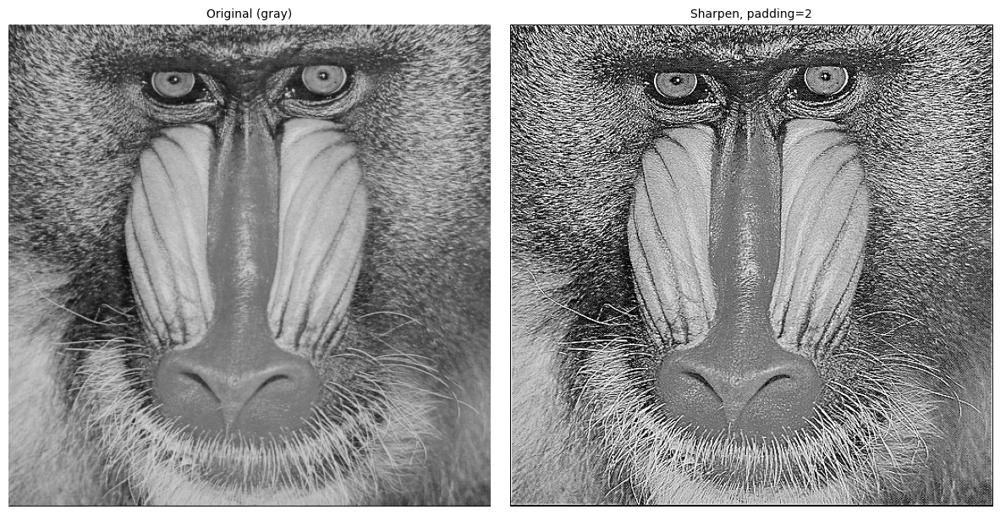

padding=1 output: (512, 512) | max difference vs cv.filter2D (check only): 0.0


In [ ]:
result = convolution2d(img_gray, kernel_sharpen, 1, 2)
print('input:', img_gray.shape, '-> output:', result.shape, '(padding 2 with a 3x3 kernel adds 2 pixels per axis)')

show_grid([('Original (gray)', img_gray),
           ('Sharpen, padding=2', to_display(result, 'clip'))], cols=2, figsize_per=(6, 6))

same = convolution2d(img_gray, kernel_sharpen, 1, 1)
ref = cv.filter2D(img_gray.astype(np.float32), cv.CV_32F, kernel_sharpen.astype(np.float32),
                  borderType=cv.BORDER_CONSTANT)
print('padding=1 output:', same.shape, '| max difference vs cv.filter2D (check only):', np.abs(same - ref).max())

**Part 3 - Average, Low Pass, High Pass and the other filters**

---

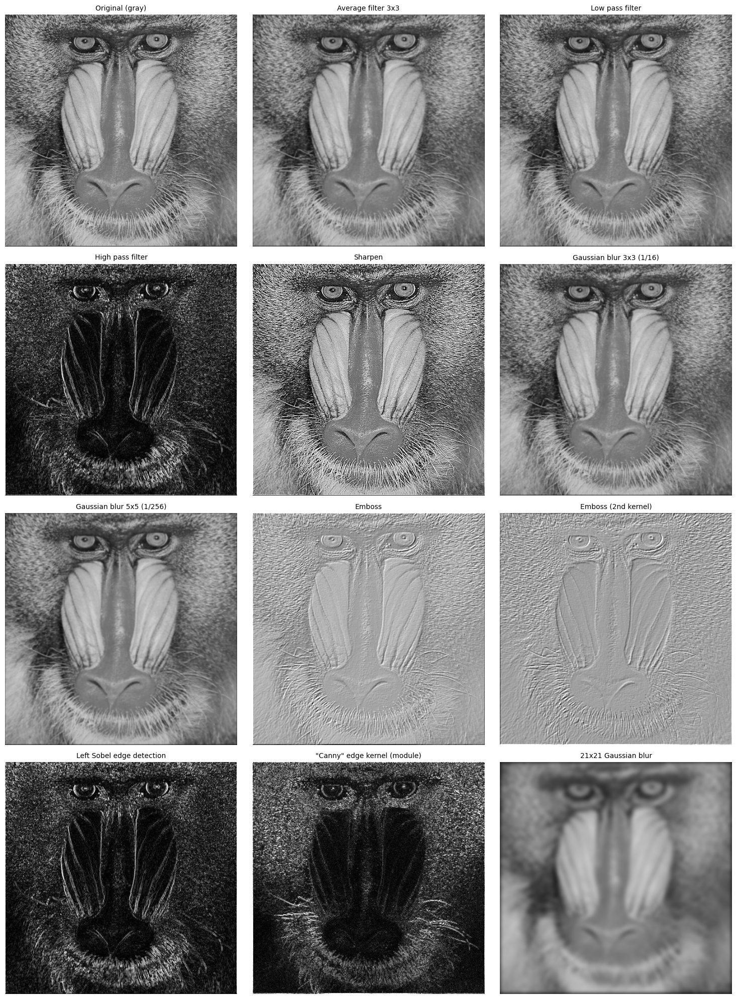

In [ ]:
sigma_k = 21
gk = cv.getGaussianKernel(sigma_k, math.sqrt(sigma_k))
gauss_kernel = gk @ gk.transpose()

kernels = [
    ('Average filter 3x3',            np.ones((3, 3)) / 9,                                          'clip'),
    ('Low pass filter',               np.array([[1, 1, 1], [1, 4, 1], [1, 1, 1]]) / 12,             'clip'),
    ('High pass filter',              np.array([[-1, 0, 1], [-1, 0, 3], [-3, 0, 1]]),               'abs'),
    ('Sharpen',                       np.array([[0, -1, 0], [-1, 5, -1], [0, -1, 0]]),              'clip'),
    ('Gaussian blur 3x3 (1/16)',      np.array([[1, 2, 1], [2, 4, 2], [1, 2, 1]]) / 16,             'clip'),
    ('Gaussian blur 5x5 (1/256)',     np.array([[1, 4, 6, 4, 1], [4, 16, 24, 16, 4], [6, 24, 36, 24, 6],
                                                [4, 16, 24, 16, 4], [1, 4, 6, 4, 1]]) / 256,        'clip'),
    ('Emboss',                        np.array([[-2, -1, 0], [-1, 1, 1], [0, 1, 2]]),               'norm'),
    ('Emboss (2nd kernel)',           np.array([[1, 0, 0], [0, 0, 0], [0, 0, -1]]),                 'norm'),
    ('Left Sobel edge detection',     np.array([[1, 0, -1], [2, 0, -2], [1, 0, -1]]),               'abs'),
    ('"Canny" edge kernel (module)',  np.array([[-1, -1, -1], [-1, 8, -1], [-1, -1, -1]]),          'abs'),
    ('21x21 Gaussian blur',           gauss_kernel,                                                 'clip'),
]

items = [('Original (gray)', img_gray)]
for name, kern, mode in kernels:
    out = convolution2d(img_gray, kern, 1, kern.shape[0] // 2)
    items.append((name, to_display(out, mode)))
show_grid(items, cols=3, figsize_per=(5, 5))

Notes on the kernels:
- Kernels whose coefficients sum to 1 (average, low pass, Gaussian, sharpen) keep the overall brightness. Kernels that sum to 0 (high pass, emboss, Sobel, edge) give about 0 on flat areas, so their response is shown as `|response|` or rescaled (`abs` / `norm` in the code).
- The "Canny" kernel in the module's table is really a Laplacian-type edge kernel. The Canny *algorithm* (`cv.Canny`) is used in Experiment 1.
- The "high pass" kernel given in the module is not symmetric, so it also emphasises a direction.

**Part 4 - Point, Line and Edge Detection**

---

**Point detection** (isolated bright/dark points give a strong response)

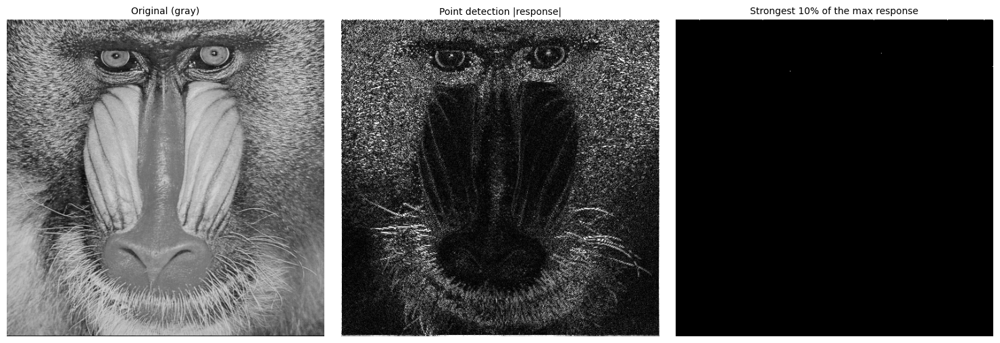

In [ ]:
kernel_point = np.array([[1, 1, 1],
                         [1, -8, 1],
                         [1, 1, 1]])
point = convolution2d(img_gray, kernel_point, 1, 1)
mask_point = (np.abs(point) >= 0.9 * np.abs(point).max()).astype(np.uint8) * 255

show_grid([('Original (gray)', img_gray),
           ('Point detection |response|', to_display(point, 'abs')),
           ('Strongest 10% of the max response', mask_point)], cols=3)

**Line detection** (four 3x3 kernels: horizontal, +45, vertical, -45)

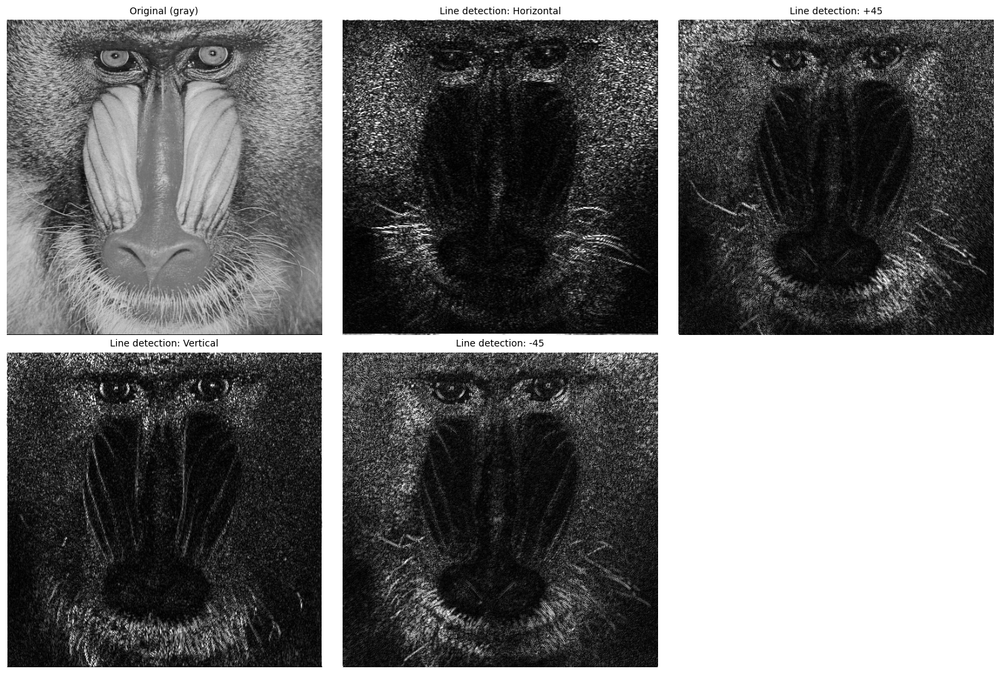

In [ ]:
line_kernels = [
    ('Horizontal', np.array([[-1, -1, -1], [ 2,  2,  2], [-1, -1, -1]])),
    ('+45',        np.array([[ 2, -1, -1], [-1,  2, -1], [-1, -1,  2]])),
    ('Vertical',   np.array([[-1,  2, -1], [-1,  2, -1], [-1,  2, -1]])),
    ('-45',        np.array([[-1, -1,  2], [-1,  2, -1], [ 2, -1, -1]])),
]
items = [('Original (gray)', img_gray)]
for name, kern in line_kernels:
    items.append(('Line detection: ' + name, to_display(convolution2d(img_gray, kern, 1, 1), 'abs')))
show_grid(items, cols=3)

**Edge detection**: Roberts, Prewitt and Sobel (gradient in x and y, then the gradient image `|gx| + |gy|`)

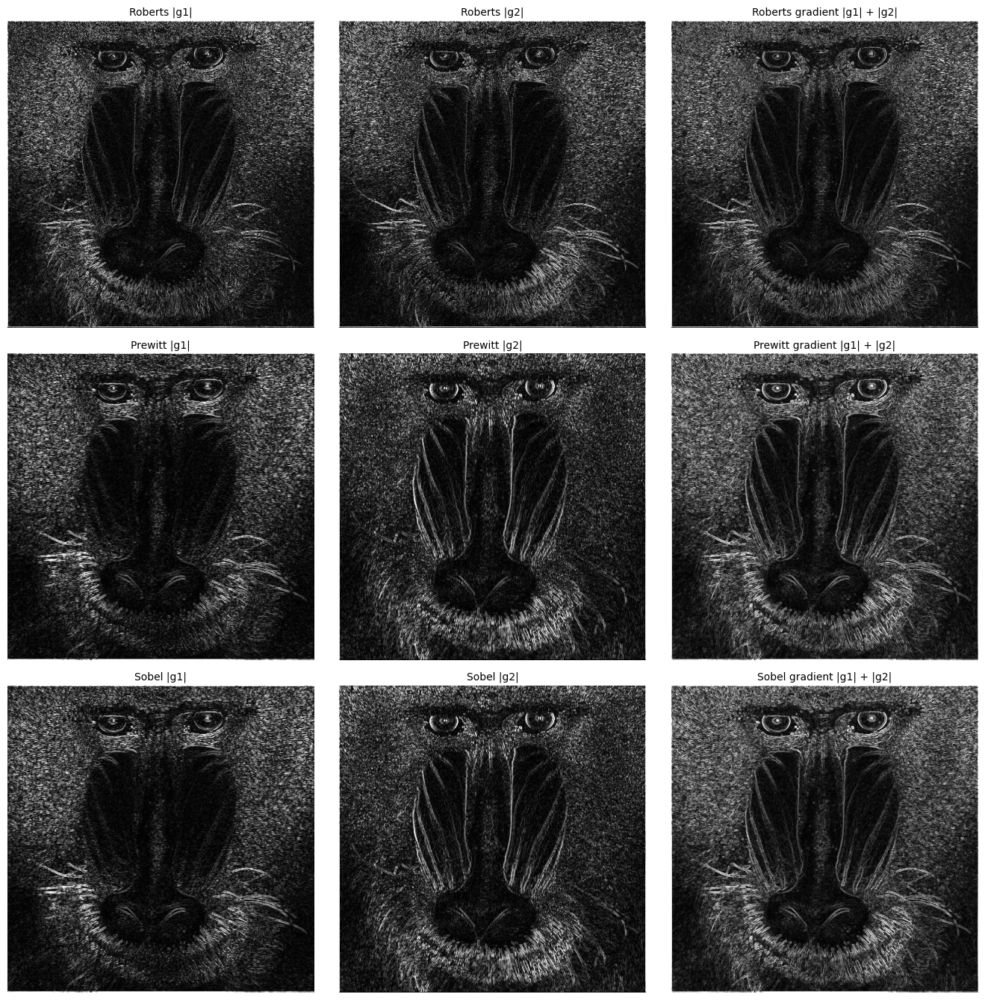

In [ ]:
operators = {
    'Roberts': (np.array([[-1, 0], [0, 1]]),                          np.array([[0, -1], [1, 0]])),
    'Prewitt': (np.array([[-1, -1, -1], [0, 0, 0], [1, 1, 1]]),       np.array([[-1, 0, 1], [-1, 0, 1], [-1, 0, 1]])),
    'Sobel':   (np.array([[-1, -2, -1], [0, 0, 0], [1, 2, 1]]),       np.array([[-1, 0, 1], [-2, 0, 2], [-1, 0, 1]])),
}
items = []
for name, (k1, k2) in operators.items():
    pad = k1.shape[0] // 2
    g1 = convolution2d(img_gray, k1, 1, pad)
    g2 = convolution2d(img_gray, k2, 1, pad)
    items += [(name + ' |g1|', to_display(g1, 'abs')),
              (name + ' |g2|', to_display(g2, 'abs')),
              (name + ' gradient |g1| + |g2|', to_display(np.abs(g1) + np.abs(g2), 'norm'))]
show_grid(items, cols=3, figsize_per=(4.5, 4.5))

**Part 5 - E. Filter Library and Modern Filter**

---

**Experiment 1** - Gaussian, Sharpen and Canny filters with the OpenCV library (`filter2D`, `GaussianBlur`, `Canny`) on an RGB image. `show_side_by_side` (defined in Part 0) shows the pictures next to each other.

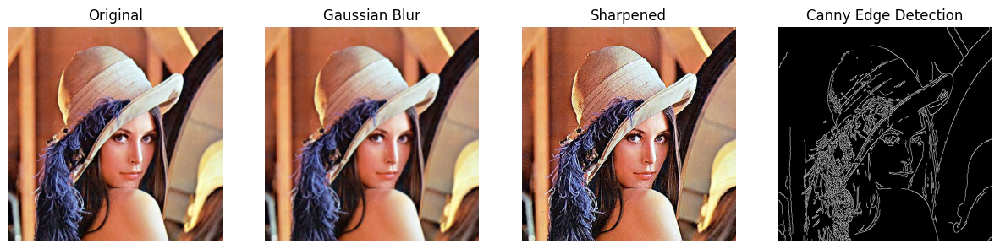

In [ ]:
img = load_image('lena.jpg')
img_gray = cv.cvtColor(img, cv.COLOR_BGR2GRAY)

blur = cv.GaussianBlur(img, (7, 7), 1)
edges = cv.Canny(cv.cvtColor(img, cv.COLOR_BGR2GRAY), 100, 200)
sharpen_kernel = np.array([[0, -1, 0], [-1, 5, -1], [0, -1, 0]])
sharpened = cv.filter2D(img, -1, sharpen_kernel)
show_side_by_side([img, blur, sharpened, edges],
                  ["Original", "Gaussian Blur", "Sharpened", "Canny Edge Detection"])

**Experiment 2** - modern filters from OpenCV: **Bilateral filtering** (smooths while keeping edges, because pixels with a very different colour get little weight) and an **edge-preserving / guided filter**. The module's code uses `cv.edgePreservingFilter` as the alternative to the guided filter; a true guided filter (`cv.ximgproc.guidedFilter`) is tried too when `opencv-contrib` is available.

cv.ximgproc is not available in this OpenCV build, skipping the guided filter.


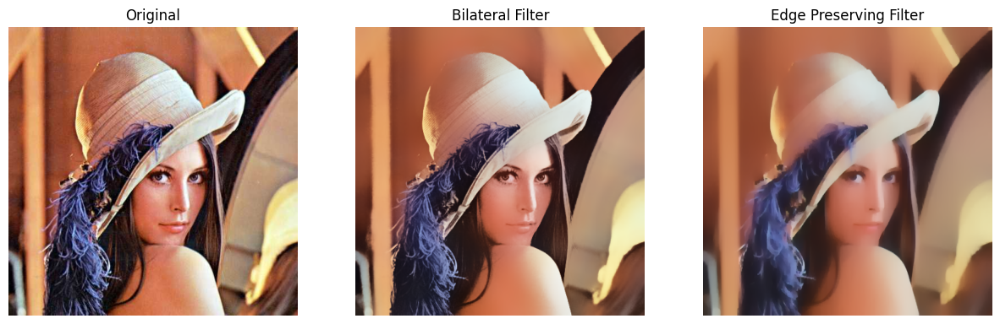

In [ ]:
bilateral = cv.bilateralFilter(img, 50, 100, 100)

edge_preserve = cv.edgePreservingFilter(img, flags=1, sigma_s=100, sigma_r=0.9)

images, titles = [img, bilateral, edge_preserve], ["Original", "Bilateral Filter", "Edge Preserving Filter"]

try:
    guided = cv.ximgproc.guidedFilter(img, img, 8, (0.1 * 255) ** 2)
    images.append(guided)
    titles.append("Guided Filter")
except AttributeError:
    print('cv.ximgproc is not available in this OpenCV build, skipping the guided filter.')

show_side_by_side(images, titles, figsize=(5 * len(images), 5))

**Experiment 3** - Filtering inside a CNN (feature maps). A convolutional layer applies many small kernels to the image and passes each result through a ReLU. Here the kernel values are **random** (He initialisation) as in an untrained network, and the generator is **not seeded**, so every run gives different feature maps. Run the cell several times and compare, then compare with a bank of hand-made kernels.

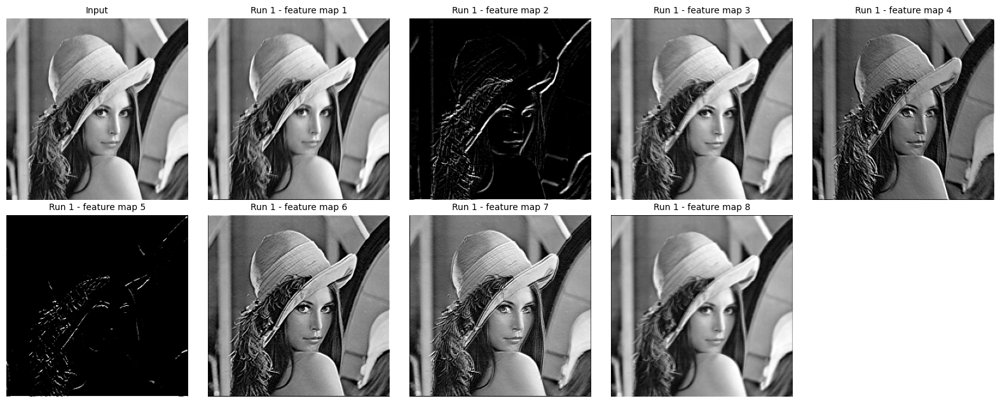

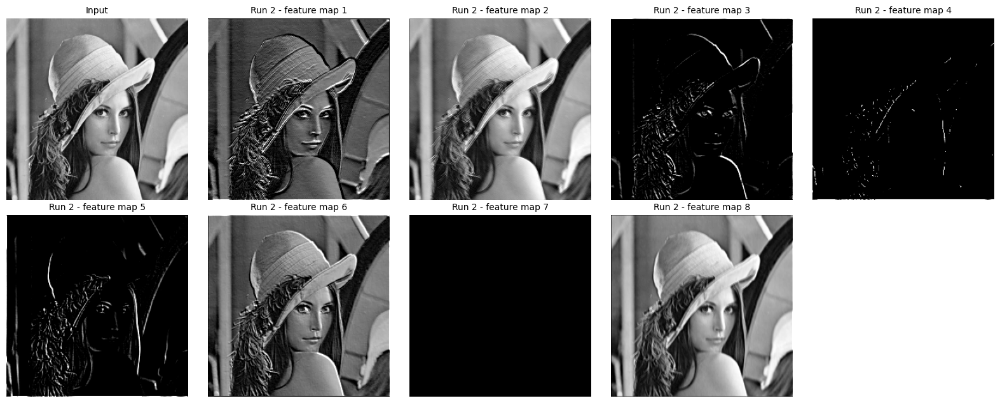

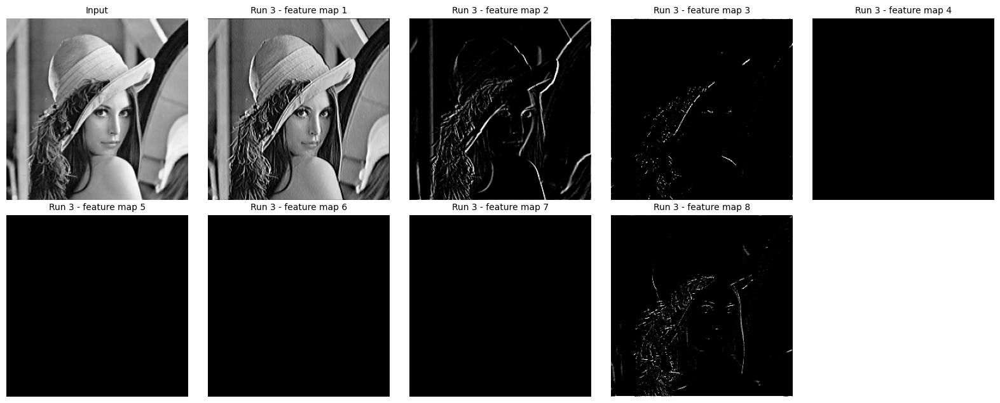

In [ ]:
rng = np.random.default_rng()

def conv_layer(gray, n_filters=8, k=3):
    x = gray.astype(np.float64) / 255.0
    maps, kernels_used = [], []
    for _ in range(n_filters):
        w = rng.normal(0, math.sqrt(2.0 / (k * k)), (k, k))
        fm = np.maximum(convolution2d(x, w, 1, k // 2), 0)
        maps.append(fm)
        kernels_used.append(w)
    return maps, kernels_used

def max_pool2x2(a):
    h, w = a.shape[0] // 2 * 2, a.shape[1] // 2 * 2
    return a[:h, :w].reshape(h // 2, 2, w // 2, 2).max(axis=(1, 3))

small = cv.resize(img_gray, (256, 256), interpolation=cv.INTER_AREA)

for run in range(1, 4):
    maps, ws = conv_layer(small)
    items = [('Input', small)]
    for i, fm in enumerate(maps, 1):
        items.append(('Run %d - feature map %d' % (run, i), to_display(fm, 'norm')))
    show_grid(items, cols=5, figsize_per=(3.2, 3.2))

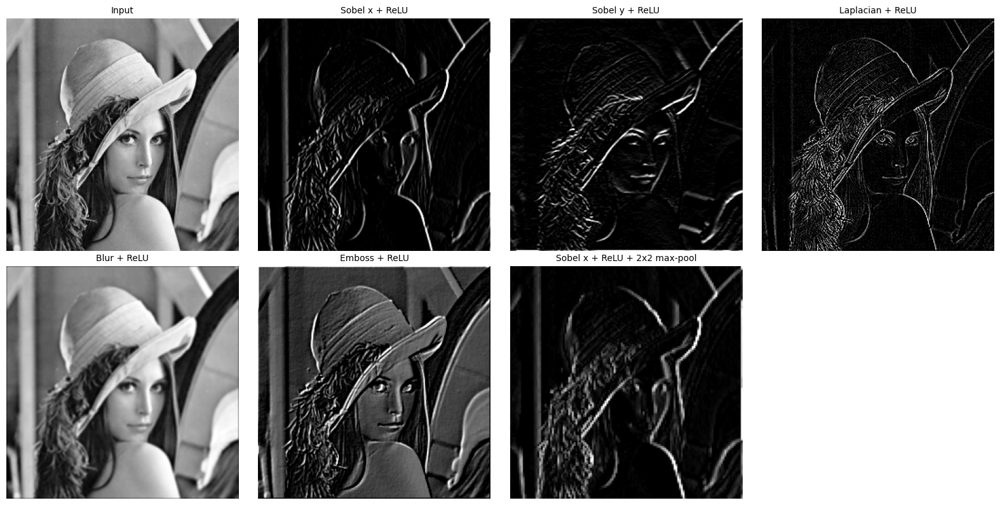

In [ ]:
bank = [('Sobel x', np.array([[1, 0, -1], [2, 0, -2], [1, 0, -1]])),
        ('Sobel y', np.array([[1, 2, 1], [0, 0, 0], [-1, -2, -1]])),
        ('Laplacian', np.array([[0, 1, 0], [1, -4, 1], [0, 1, 0]])),
        ('Blur', np.ones((3, 3)) / 9),
        ('Emboss', np.array([[-2, -1, 0], [-1, 1, 1], [0, 1, 2]]))]
x = small.astype(np.float64) / 255.0
items = [('Input', small)]
for name, kern in bank:
    items.append((name + ' + ReLU', to_display(np.maximum(convolution2d(x, kern, 1, 1), 0), 'norm')))
items.append(('Sobel x + ReLU + 2x2 max-pool', to_display(max_pool2x2(np.maximum(convolution2d(x, bank[0][1], 1, 1), 0)), 'norm')))
show_grid(items, cols=4, figsize_per=(4, 4))

**Conclusion for Experiment 3**

- **Every run is different.** The kernels are random, so the feature maps change on each run. In run 1, six of the eight maps are smooth or lightly sharpened copies of the input, while maps 2 and 5 show only thin edges on a black background. In run 2, map 1 is a strong relief/edge version, maps 3 to 5 are sparse edges, and map 7 is completely black.
- **Why they differ.** A kernel whose weights sum to a clearly positive number keeps most of the image (blur-like or copy-like map). A kernel whose weights sum to about zero only responds at edges, and after ReLU the flat areas become black. A completely black map (a "dead" filter) happens when every response is negative or zero, so ReLU removes all of it.
- **ReLU and pooling.** ReLU keeps only the positive side of each edge (for Sobel x only one side of each vertical edge remains), and 2x2 max-pooling halves the map size while keeping the strongest response.
- **Conclusion.** What a convolution layer extracts depends entirely on its kernel values. In a CNN these values are not designed by hand and not left random: they are learned by training, so that the network ends up with kernels that detect edges, lines and textures useful for its task.

**Experiment 4** - Beauty and Vintage effects built only from traditional filters.

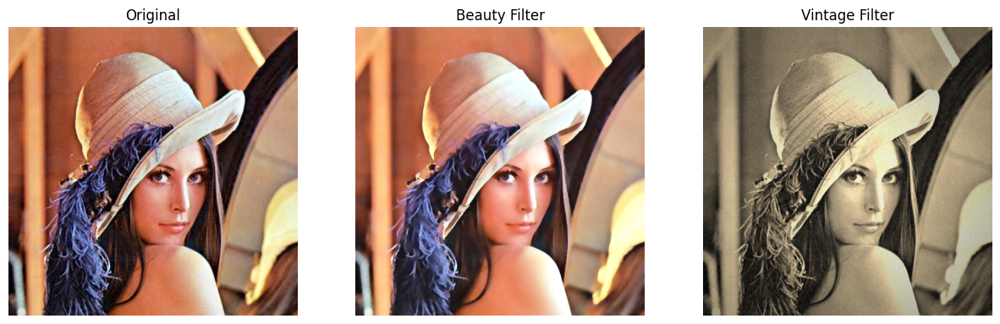

In [ ]:
def beauty_filter(image, strength=0.7):
    smooth = cv.bilateralFilter(image, 9, 75, 75)
    smooth = cv.bilateralFilter(smooth, 9, 75, 75)
    blended = cv.addWeighted(smooth, strength, image, 1 - strength, 0)
    return cv.convertScaleAbs(blended, alpha=1.05, beta=10)

def vintage_filter(image):
    sepia = np.array([[0.131, 0.534, 0.272],
                      [0.168, 0.686, 0.349],
                      [0.189, 0.769, 0.393]])
    out = np.clip(cv.transform(image.astype(np.float32), sepia), 0, 255)
    out = out * 0.9 + 15
    h, w = image.shape[:2]
    kx = cv.getGaussianKernel(w, w / 2)
    ky = cv.getGaussianKernel(h, h / 2)
    vignette = ky @ kx.T
    vignette = vignette / vignette.max()
    out = out * (0.4 + 0.6 * vignette[:, :, None])
    out = out + np.random.default_rng(0).normal(0, 8, out.shape)
    return np.clip(out, 0, 255).astype(np.uint8)

show_side_by_side([img, beauty_filter(img), vintage_filter(img)],
                  ["Original", "Beauty Filter", "Vintage Filter"])

**Experiment 5** - Anime / cartoon filter from a combination of traditional filters.

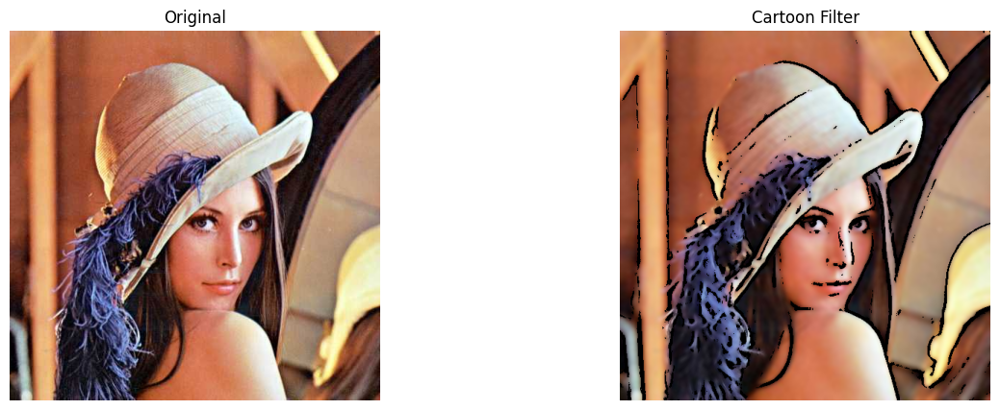

In [ ]:
gray = cv.cvtColor(img, cv.COLOR_BGR2GRAY)
gray_blur = cv.medianBlur(gray, 7)
edges = cv.adaptiveThreshold(gray_blur, 255,
                             cv.ADAPTIVE_THRESH_MEAN_C,
                             cv.THRESH_BINARY, 9, 9)

color = cv.bilateralFilter(img, d=9, sigmaColor=200, sigmaSpace=200)

cartoon_img = cv.bitwise_and(color, color, mask=edges)

show_side_by_side([img, cartoon_img], ["Original", "Cartoon Filter"])

**Experiment 6** - Night filter: darken, add a colour bias, then a glow on the bright areas made with a `filter2D` blur kernel. If `djawatan.jpg` is not in the Images folder, `lena.jpg` is used instead.

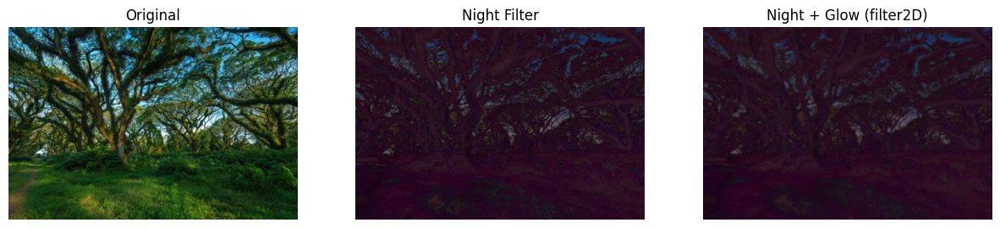

In [ ]:
img_night = load_image('djawatan.jpg', fallback='lena.jpg')

night = cv.convertScaleAbs(img_night, alpha=0.6, beta=-40)

blue_tint = np.full_like(night, (50, 0, 100))
night = cv.addWeighted(night, 0.8, blue_tint, 0.2, 0)

kernel = np.ones((15, 15), np.float32) / 225
glow = cv.filter2D(night, -1, kernel)

night_glow = cv.addWeighted(night, 0.7, glow, 0.3, 0)

show_side_by_side([img_night, night, night_glow],
                  ["Original", "Night Filter", "Night + Glow (filter2D)"])

**Experiment 7** - Morning and Evening filters with a fog effect.

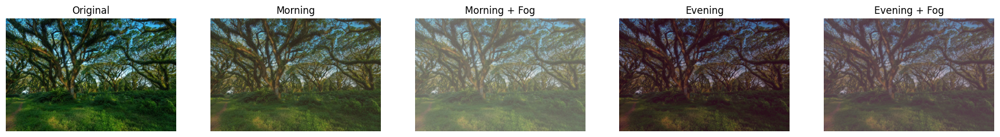

In [ ]:
img_tree = img_night

alpha = 0.9
beta = 20
soft = cv.convertScaleAbs(img_tree, alpha=alpha, beta=beta)

warm_tint = np.full_like(soft, (40, 70, 120))
morning = cv.addWeighted(soft, 0.8, warm_tint, 0.2, 0)

kernel = cv.getGaussianKernel(3, 3)
kernel = kernel @ kernel.T
fog = cv.filter2D(morning, -1, kernel)

white_layer = np.full_like(morning, 255)
fog = cv.addWeighted(fog, 0.7, white_layer, 0.3, 0)

evening_base = cv.convertScaleAbs(img_tree, alpha=0.8, beta=-10)
evening = cv.addWeighted(evening_base, 0.75, np.full_like(evening_base, (90, 40, 150)), 0.25, 0)
evening_fog = cv.addWeighted(cv.filter2D(evening, -1, kernel), 0.8, white_layer, 0.2, 0)

show_side_by_side([img_tree, morning, fog, evening, evening_fog],
                  ["Original", "Morning", "Morning + Fog", "Evening", "Evening + Fog"], figsize=(22, 4))

**Task Practicum 1: Mean Filter vs Median Filter on Salt and Pepper noise**

---

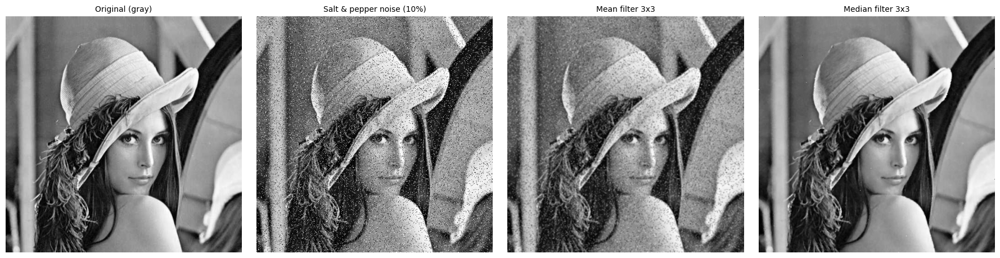

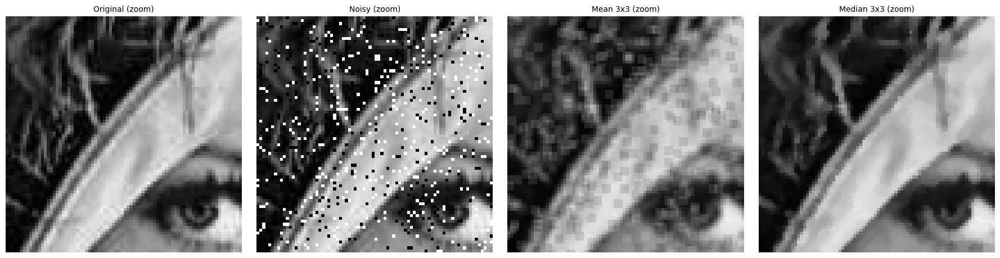

In [ ]:
def add_salt_pepper(gray, amount=0.1, seed=0):
    r = np.random.default_rng(seed).random(gray.shape)
    noisy = gray.copy()
    noisy[r < amount / 2] = 0
    noisy[(r >= amount / 2) & (r < amount)] = 255
    return noisy

def mean_filter(gray):
    return np.clip(convolution2d(gray, np.ones((3, 3)) / 9, 1, 1, mode='replicate'), 0, 255).astype(np.uint8)

def median_filter(gray):
    return cv.medianBlur(gray, 3)

clean = cv.cvtColor(load_image('lena.jpg'), cv.COLOR_BGR2GRAY)
noisy = add_salt_pepper(clean, 0.1)
mean_out = mean_filter(noisy)
median_out = median_filter(noisy)

assert np.abs(mean_out.astype(int) - cv.blur(noisy, (3, 3), borderType=cv.BORDER_REPLICATE).astype(int)).max() <= 1

show_grid([('Original (gray)', clean), ('Salt & pepper noise (10%)', noisy),
           ('Mean filter 3x3', mean_out), ('Median filter 3x3', median_out)], cols=4, figsize_per=(4.5, 4.5))

y0, x0, s = 200, 200, 80
crops = [clean, noisy, mean_out, median_out]
names = ['Original', 'Noisy', 'Mean 3x3', 'Median 3x3']
show_grid([(n + ' (zoom)', c[y0:y0 + s, x0:x0 + s]) for n, c in zip(names, crops)], cols=4, figsize_per=(4.5, 4.5))

In [ ]:
print('%-10s | %-22s | %-22s | %-22s' % ('noise', 'noisy image', 'mean 3x3', 'median 3x3'))
print('%-10s | %-22s | %-22s | %-22s' % ('amount', 'PSNR (dB)', 'PSNR (dB)', 'PSNR (dB)'))
for amount in [0.02, 0.05, 0.10, 0.20]:
    n = add_salt_pepper(clean, amount)
    print('%-10s | %-22.2f | %-22.2f | %-22.2f' % ('%d%%' % round(amount * 100),
                                                    calculate_psnr(clean, n),
                                                    calculate_psnr(clean, mean_filter(n)),
                                                    calculate_psnr(clean, median_filter(n))))

noise      | noisy image            | mean 3x3               | median 3x3            
amount     | PSNR (dB)              | PSNR (dB)              | PSNR (dB)             
2%         | 22.09                  | 28.63                  | 33.63                 
5%         | 18.11                  | 25.90                  | 33.07                 
10%        | 15.00                  | 23.10                  | 31.97                 
20%        | 12.01                  | 19.93                  | 28.43                 


**Analysis (Task 1c)**

| Noise | Noisy | Mean 3x3 | Median 3x3 | Median advantage |
|---|---|---|---|---|
| 2% | 22.09 dB | 28.63 dB | 33.63 dB | +5.00 dB |
| 5% | 18.11 dB | 25.90 dB | 33.07 dB | +7.17 dB |
| 10% | 15.00 dB | 23.10 dB | 31.97 dB | +8.87 dB |
| 20% | 12.01 dB | 19.93 dB | 28.43 dB | +8.50 dB |

- **Mean filter:** each output pixel is the average of its 3x3 neighbourhood. A noise pixel (0 or 255) is far from the true value, so it pulls the average away. In the zoom the noise is not removed but spread into grey 3x3 blotches, and the edges of the hat and the eye also become blurred.
- **Median filter:** each output pixel is the middle value of the sorted 3x3 values. A salt or pepper pixel is an extreme value, so it ends up at the end of the sorted list and is discarded. In the zoom the result is almost clean, and the edges stay sharp because the median is always one of the real neighbouring values.
- **Numbers:** the median is better at every noise level, by 5 to 9 dB. When the noise grows from 2% to 20%, the median loses 5.2 dB while the mean loses 8.7 dB. Even at 20% noise the median (28.43 dB) is about as good as the mean at 2% noise (28.63 dB).
- **Conclusion:** for salt and pepper noise the median filter is far cleaner, because the noise values are outliers that the median ignores but the mean averages in.

**Task Practicum 2: Best kernel size for sharpening**

---

A sharpening kernel is built in two sizes: 3x3 and 5x5. They are applied to a slightly blurry image and compared on **edge clarity** (mean gradient magnitude, higher = crisper) and on **noise**.

The blurry image is made from the sharp `lena.jpg` (Gaussian blur, sigma 1.5), so the sharp original can serve as a reference (PSNR). To measure noise amplification, the same kernels are also applied to a copy with a little Gaussian noise (sigma 3); the *noise gain* is the standard deviation of the noise after the kernel divided by the standard deviation before it (1.0 = no amplification). To use your own blurry photo, replace `sharp` and `blurry` below.

3x3 Laplacian sharpen (module)     kernel sum = 1.00
3x3 unsharp (2*delta - Gauss3)     kernel sum = 1.00
5x5 unsharp (2*delta - Gauss5)     kernel sum = 1.00

image                              | edge clarity | PSNR vs sharp (dB) | noise gain
Sharp original (reference)         | 62.60        | -                  | -         
Blurry input (no filter)           | 39.97        | 28.04              | 1.00      
3x3 Laplacian sharpen (module)     | 49.42        | 30.95              | 5.38      
3x3 unsharp (2*delta - Gauss3)     | 42.19        | 28.77              | 1.77      
5x5 unsharp (2*delta - Gauss5)     | 44.00        | 29.36              | 1.87      


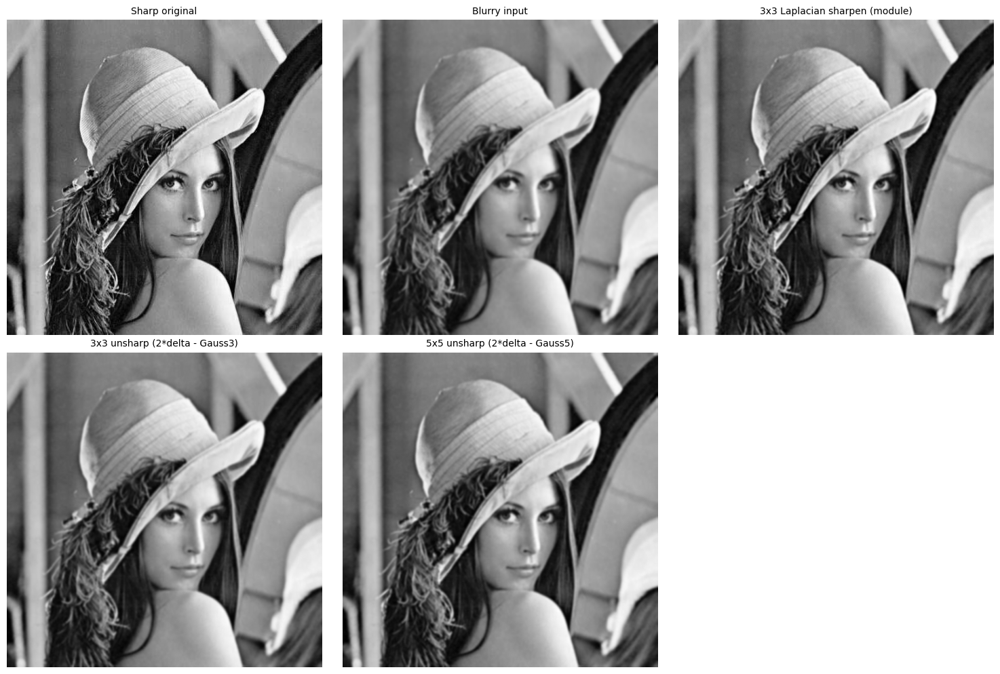

In [ ]:
sharp = cv.cvtColor(load_image('lena.jpg'), cv.COLOR_BGR2GRAY)
blurry = cv.GaussianBlur(sharp, (0, 0), 1.5)
noise = np.random.default_rng(1).normal(0, 3, blurry.shape)
blurry_noisy = np.clip(blurry + noise, 0, 255)

delta3 = np.zeros((3, 3)); delta3[1, 1] = 1
delta5 = np.zeros((5, 5)); delta5[2, 2] = 1
g3 = np.array([[1, 2, 1], [2, 4, 2], [1, 2, 1]]) / 16
g5 = np.array([[1, 4, 6, 4, 1], [4, 16, 24, 16, 4], [6, 24, 36, 24, 6],
               [4, 16, 24, 16, 4], [1, 4, 6, 4, 1]]) / 256

sharpen_kernels = [
    ('3x3 Laplacian sharpen (module)', np.array([[0, -1, 0], [-1, 5, -1], [0, -1, 0]])),
    ('3x3 unsharp (2*delta - Gauss3)', 2 * delta3 - g3),
    ('5x5 unsharp (2*delta - Gauss5)', 2 * delta5 - g5),
]
for n_, k_ in sharpen_kernels:
    print('%-34s kernel sum = %.2f' % (n_, k_.sum()))

def gradient_strength(gray):
    gx = cv.Sobel(gray.astype(np.float32), cv.CV_32F, 1, 0)
    gy = cv.Sobel(gray.astype(np.float32), cv.CV_32F, 0, 1)
    return float(np.mean(np.sqrt(gx ** 2 + gy ** 2)))

rows = [('Sharp original (reference)', sharp, None, None),
        ('Blurry input (no filter)', blurry, calculate_psnr(sharp, blurry), 1.0)]
outputs = []
for name, kern in sharpen_kernels:
    p = kern.shape[0] // 2
    out_clean = convolution2d(blurry, kern, 1, p, mode='replicate')
    out_noisy = convolution2d(blurry_noisy, kern, 1, p, mode='replicate')
    gain = np.std(out_noisy - out_clean) / np.std(blurry_noisy - blurry)
    out_u8 = np.clip(out_clean, 0, 255).astype(np.uint8)
    outputs.append((name, out_u8))
    rows.append((name, out_u8, calculate_psnr(sharp, out_u8), gain))

print('\n%-34s | %-12s | %-18s | %-10s' % ('image', 'edge clarity', 'PSNR vs sharp (dB)', 'noise gain'))
for name, im_, psnr_, gain_ in rows:
    print('%-34s | %-12.2f | %-18s | %-10s' % (name, gradient_strength(im_),
          '-' if psnr_ is None else '%.2f' % psnr_, '-' if gain_ is None else '%.2f' % gain_))

show_grid([('Sharp original', sharp), ('Blurry input', blurry)] + outputs, cols=3, figsize_per=(5, 5))

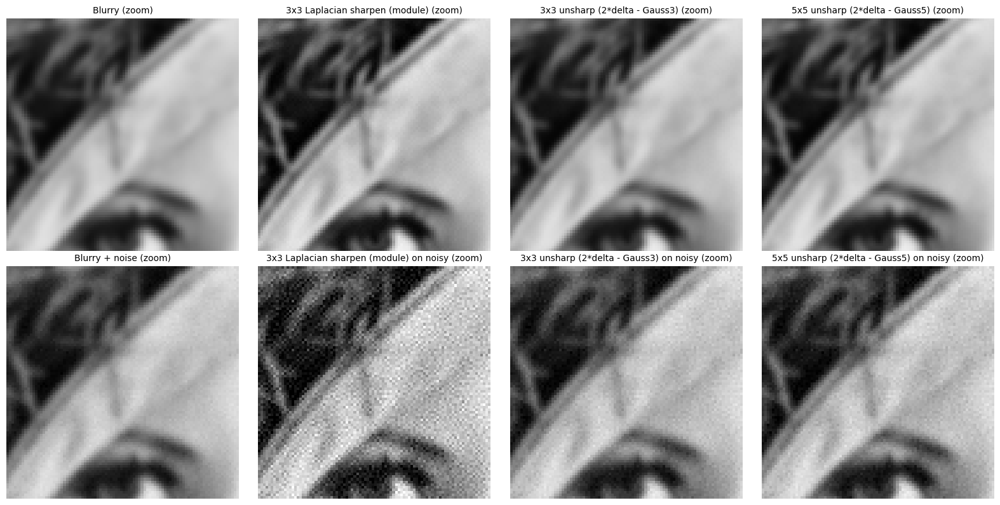

In [ ]:
y0, x0, s = 180, 220, 90
noisy_outputs = [(name, np.clip(convolution2d(blurry_noisy, kern, 1, kern.shape[0] // 2, mode='replicate'), 0, 255))
                 for name, kern in sharpen_kernels]
show_grid([('Blurry (zoom)', blurry[y0:y0 + s, x0:x0 + s])] +
          [(n + ' (zoom)', o[y0:y0 + s, x0:x0 + s]) for n, o in outputs] +
          [('Blurry + noise (zoom)', blurry_noisy[y0:y0 + s, x0:x0 + s])] +
          [(n + ' on noisy (zoom)', o[y0:y0 + s, x0:x0 + s]) for n, o in noisy_outputs], cols=4, figsize_per=(4, 4))

**Evaluation (Task 2c)**

| Kernel | Edge clarity | PSNR vs sharp | Noise gain |
|---|---|---|---|
| Blurry input | 39.97 | 28.04 dB | 1.00 |
| 3x3 Laplacian sharpen (module) | 49.42 | 30.95 dB | 5.38 |
| 3x3 unsharp | 42.19 | 28.77 dB | 1.77 |
| 5x5 unsharp | 44.00 | 29.36 dB | 1.87 |

The sharp original has an edge clarity of 62.60.

- **Edge clarity:** the module's 3x3 kernel gives the biggest gain (+9.45), the 5x5 unsharp kernel gives +4.03 and the 3x3 unsharp kernel only +2.22. None of them overshoots the original (62.60), so there is no strong over-sharpening.
- **Noise:** the module's 3x3 kernel multiplies the noise by 5.38. In the zoom on the noisy image it produces heavy grain, while both unsharp kernels stay clean (gain 1.77 and 1.87).
- **3x3 vs 5x5 unsharp:** the 5x5 kernel nearly doubles the clarity gain of the 3x3 one (+4.03 vs +2.22) and has a higher PSNR (29.36 vs 28.77 dB), for almost the same noise gain (1.87 vs 1.77).
- **Decision:** the 5x5 unsharp kernel is the most optimal for daily use, because real photos always contain some noise and it gives the best clarity for a small noise cost. The module's 3x3 kernel is only a good choice for very clean images, where its strong effect and highest PSNR (30.95 dB) are useful.

**Task Practicum 3: Simple Cartoon Filter**

---

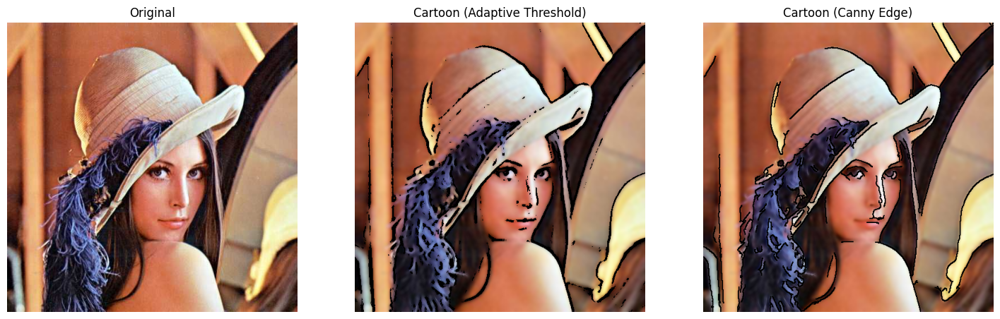

In [ ]:
def cartoon(image, method='adaptive'):
    color = cv.bilateralFilter(image, d=9, sigmaColor=200, sigmaSpace=200)

    gray = cv.medianBlur(cv.cvtColor(image, cv.COLOR_BGR2GRAY), 7)
    if method == 'adaptive':
        edges = cv.adaptiveThreshold(gray, 255, cv.ADAPTIVE_THRESH_MEAN_C, cv.THRESH_BINARY, 9, 9)
    elif method == 'canny':
        canny = cv.Canny(gray, 100, 200)
        edges = 255 - cv.dilate(canny, np.ones((2, 2), np.uint8))
    else:
        raise ValueError("method must be 'adaptive' or 'canny'")

    mask = (edges / 255.0)[:, :, None]
    return (color * mask).astype(np.uint8)

original = load_image('lena.jpg')
show_side_by_side([original, cartoon(original, 'adaptive'), cartoon(original, 'canny')],
                  ["Original", "Cartoon (Adaptive Threshold)", "Cartoon (Canny Edge)"], figsize=(18, 6))